# Attempt 004 — 300 blind judgments by this Codex assistant

All judgments and confidence bins were sealed and committed **before** human labels
were loaded. No other model, subagent or web lookup was used for judging. This is
a comparison of judging setups, with full conversations for Codex and truncated
input for Gemma, rather than an isolated test of model parameter count.


In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
repo=Path.cwd()
if repo.name=='notebooks':repo=repo.parent
r=json.loads((repo/'results/attempt_004_self_judge/results.json').read_text())
names={'codex_blind_subjective':'Codex blind','gemma26_2048_original':'Gemma 2048',
       'gemma26_1024_original':'Gemma 1024','qwen3_4b_lora_frozen':'Qwen3-4B LoRA','training_prior':'Class prior'}
print('Sealed before targets in commit:',r['seal_commit'])
print('Judgment hash:',r['frozen']['judgments_sha256'])
print('Human label counts A/B/tie:',r['human_label_counts'])
table=pd.DataFrame([{'judge':names[x['model']],'correct':x['correct'],'accuracy':x['accuracy'],
 'direct_log_loss':x['log_loss'],
 'CV_temperature_tie_loss':x.get('cross_fitted_temperature_tie',{}).get('log_loss'),
 'fixed_alpha_best_same_rows':x['fixed_alpha_fitted_log_loss'],
 'fixed_alpha_CV_loss':x['fixed_alpha_cross_fitted_log_loss']} for x in r['models']])
display(table)
assert len(r['models'])==5 and all(x['rows']==300 for x in r['models'])
assert r['models'][0]['correct']==169


Sealed before targets in commit: 91ba921089a8b696091cbc8ab7e3832fb75e4000
Judgment hash: ce046e96eb320cb2075980a28cabb6d3d46f14af7e3365e9ca925c34ed56f98c
Human label counts A/B/tie: [101, 103, 96]


,judge,correct,accuracy,direct_log_loss,CV_temperature_tie_loss,fixed_alpha_best_same_rows,fixed_alpha_CV_loss
0,Codex blind,169,0.563333,0.978696,0.964476,0.987778,0.991711
1,Gemma 2048,160,0.533333,1.414246,0.977080,1.014392,1.015171
2,Gemma 1024,154,0.513333,1.436833,1.006946,1.030123,1.031959
3,Qwen3-4B LoRA,156,0.520000,0.963078,0.967306,1.025058,1.031022
4,Class prior,101,0.336667,1.098596,NaN,1.098587,1.098612


Direct Codex probabilities use subjective confidence bins of 0.4, 0.5, 0.6,
0.7 and 0.8 for the chosen class, sharing the remainder equally. They are **not**
token likelihoods. The CV calibration column fits temperature and a tie intercept
on four folds and scores the fifth; all 300 prompt groups are distinct. Its argmax
accuracy may change. Qwen's direct probabilities use its original frozen calibration.
The best same-row alpha is optimistic; CV alpha instead uses each training fold's accuracy.


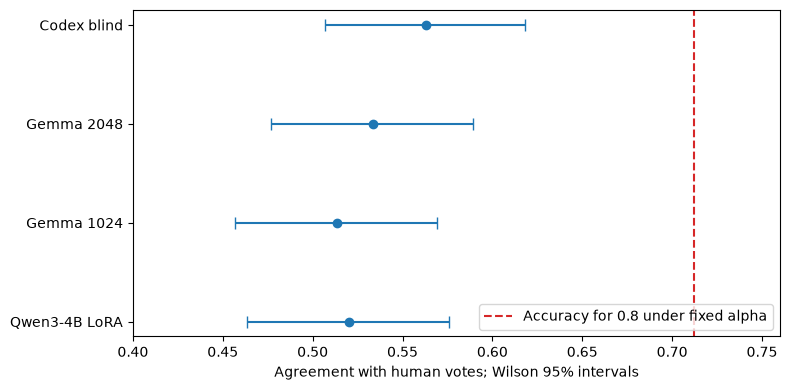

,against,accuracy_gain,accuracy_gain_95,self_only_correct,other_only_correct,mcnemar_exact_p
0,gemma26_2048_original,0.030000,"[-0.026667, 0.09]",43,34,3.620318e-01
1,gemma26_1024_original,0.050000,"[-0.01, 0.11]",47,32,1.146604e-01
2,qwen3_4b_lora_frozen,0.043333,"[-0.023417, 0.113333]",62,49,2.546051e-01
3,training_prior,0.226667,"[0.159917, 0.296667]",97,29,9.244792e-10


In [2]:
fig,ax=plt.subplots(figsize=(8,4))
models=r['models'][:-1]
values=np.array([x['accuracy'] for x in models])
ci=np.array([x['accuracy_wilson_95'] for x in models])
ax.errorbar(values,np.arange(len(models)),xerr=[values-ci[:,0],ci[:,1]-values],fmt='o',capsize=4)
ax.set_yticks(np.arange(len(models)),[names[x['model']] for x in models])
ax.axvline(.7119859693,color='tab:red',linestyle='--',label='Accuracy for 0.8 under fixed alpha')
ax.set(xlabel='Agreement with human votes; Wilson 95% intervals',xlim=(.4,.76))
ax.invert_yaxis();ax.legend(loc='lower right');fig.tight_layout()
figures=Path.home()/'database/llm_classification_finetuning/runs/attempt_004_self_judge/figures'
figures.mkdir(exist_ok=True)
fig.savefig(figures/'accuracy.png',dpi=160)
plt.show()
display(pd.DataFrame(r['paired'])[['against','accuracy_gain','accuracy_gain_95',
                                 'self_only_correct','other_only_correct','mcnemar_exact_p']])


The 3-point advantage over 2,048-token Gemma is uncertain: paired 95% interval
**−2.67 to +9.00 percentage points**, exact McNemar p=0.362. These data do not
establish a reliable accuracy improvement and do not approach the fixed-alpha 71.2% target.


,Codex A,Codex B,Codex tie
Human A,72,19,10
Human B,28,62,13
Human tie,36,25,35


,error,rows
0,Missed human tie,61
1,Predicted tie; human chose winner,23
2,Reversed A/B vote,47


,level,nominal_probability,rows,accuracy
0,low,0.4,3,1.000000
1,medium,0.5,64,0.437500
2,good,0.6,74,0.472973
3,high,0.7,95,0.536842
4,very_high,0.8,64,0.812500


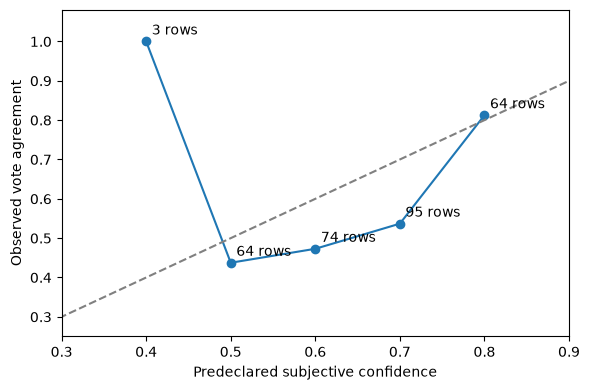

In [3]:
cm=np.array(r['models'][0]['confusion_matrix'])
display(pd.DataFrame(cm,index=['Human A','Human B','Human tie'],columns=['Codex A','Codex B','Codex tie']))
missed_ties=int(cm[2,:2].sum()); extra_ties=int(cm[:2,2].sum())
wrong_winner=int(cm[0,1]+cm[1,0])
assert missed_ties+extra_ties+wrong_winner==300-r['models'][0]['correct']
display(pd.DataFrame({'error':['Missed human tie','Predicted tie; human chose winner','Reversed A/B vote'],
                      'rows':[missed_ties,extra_ties,wrong_winner]}))
display(pd.DataFrame(r['confidence_reliability']))
fig,ax=plt.subplots(figsize=(6,4))
reliability=r['confidence_reliability']
ax.plot([x['nominal_probability'] for x in reliability],[x['accuracy'] for x in reliability],'o-')
for x in reliability:ax.annotate(str(x['rows'])+' rows',(x['nominal_probability'],x['accuracy']),xytext=(4,5),textcoords='offset points')
ax.plot([0,1],[0,1],'--',color='gray')
ax.set(xlabel='Predeclared subjective confidence',ylabel='Observed vote agreement',xlim=(.3,.9),ylim=(.25,1.08))
fig.tight_layout();fig.savefig(figures/'confidence_reliability.png',dpi=160);plt.show()


Codex predicts 58 ties versus 96 recorded ties and recovers only 35 of those 96.
Missed ties account for 61 of 131 errors. On human-decisive cases Codex agrees on
134/204 (65.69%), versus Gemma's 140/204 (68.63%). The net gain comes from tie
recognition, despite weaker agreement on decisive votes.

These disagreements can reflect individual preferences, rubric mismatch, human
annotation noise **or mistakes by the current assistant**. They do not establish
which cause dominates. Judgments and reasons remain unchanged after unblinding.


In [4]:
print(json.dumps(r['protocol'],indent=2))
for note in r['notes']:print('-',note)


{
  "attempt": "004_self_judge",
  "rows": 300,
  "seed": 20261116,
  "eligible_rows_after_exclusions": 496,
  "sample_source": "Unique prompt groups in existing fixed 512-row Gemma development sample; exclude poster/manual-review IDs",
  "confidence_mapping": {
    "low": 0.4,
    "medium": 0.5,
    "good": 0.6,
    "high": 0.7,
    "very_high": 0.8
  },
  "probability_rule": "Chosen class gets confidence; each other class gets (1-confidence)/2",
  "judge": "Current Codex assistant itself; no other models, subagents, web lookup or winner feedback",
  "input": "Complete conversations, randomized answer order, hidden row IDs and model identities",
  "inputs_sha256": "8dc11810f85c2bc47ef3760bee23917caca20e63492f94174cca2ee1351a613c",
  "mapping_sha256": "0c6862c6962d7fa6666d8cce175d42041e0ec9ff5b6300dbf3f34647a917a3ca",
  "targets_loaded": false,
  "limitations": [
    "Not a clean pretraining-contamination benchmark: the public dataset may have been in model training.",
    "Full contex

Full inputs, anonymization mapping, subjective judgments, reasons and scored
row-level results are under `~/database/llm_classification_finetuning/runs/attempt_004_self_judge`.
No raw conversations are included in this notebook. See `ATTEMPT_004_RESULTS.md`
and the prepare/show/record/freeze code in `scripts/blind_self_judge.py`.

The public dataset may have appeared in pretraining, the exact current assistant
checkpoint is not established, and the sample previously served model development.
Different context lengths, quantization and reasoning also limit causal claims about model level.
